In [1]:
import pandas as pd

url = 'https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-02-car-price/data.csv'
df = pd.read_csv(url)

# Save locally to 'data.csv'
df.to_csv('02-regression/data.csv', index=False)

In [2]:
df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [3]:
df.columns.str.lower()

Index(['make', 'model', 'year', 'engine fuel type', 'engine hp',
       'engine cylinders', 'transmission type', 'driven_wheels',
       'number of doors', 'market category', 'vehicle size', 'vehicle style',
       'highway mpg', 'city mpg', 'popularity', 'msrp'],
      dtype='str')

In [4]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [5]:
df.dtypes

make                     str
model                    str
year                   int64
engine_fuel_type         str
engine_hp            float64
engine_cylinders     float64
transmission_type        str
driven_wheels            str
number_of_doors      float64
market_category          str
vehicle_size             str
vehicle_style            str
highway_mpg            int64
city_mpg               int64
popularity             int64
msrp                   int64
dtype: object

In [6]:
df.dtypes[df.dtypes == 'object']

Series([], dtype: object)

In [7]:
pd.__version__

'3.0.6'

In [8]:

# Selects both 'object' and 'string' columns reliably (panda version = 3.0.6 => 'string' type is showing and not object)
string_columns = list(df.select_dtypes(include=['object', 'string']).columns)
string_columns

['make',
 'model',
 'engine_fuel_type',
 'transmission_type',
 'driven_wheels',
 'market_category',
 'vehicle_size',
 'vehicle_style']

In [9]:
for col in string_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_')

In [10]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,bmw,1_series_m,2011,premium_unleaded_(required),335.0,6.0,manual,rear_wheel_drive,2.0,"factory_tuner,luxury,high-performance",compact,coupe,26,19,3916,46135
1,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,convertible,28,19,3916,40650
2,bmw,1_series,2011,premium_unleaded_(required),300.0,6.0,manual,rear_wheel_drive,2.0,"luxury,high-performance",compact,coupe,28,20,3916,36350
3,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,"luxury,performance",compact,coupe,28,18,3916,29450
4,bmw,1_series,2011,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,34500


In [11]:
for col in df.columns:
    print(col)
    print(df[col].unique()[:5])
    print(df[col].nunique())
    print()

make
<StringArray>
['bmw', 'audi', 'fiat', 'mercedes-benz', 'chrysler']
Length: 5, dtype: str
48

model
<StringArray>
['1_series_m', '1_series', '100', '124_spider', '190-class']
Length: 5, dtype: str
914

year
[2011 2012 2013 1992 1993]
28

engine_fuel_type
<StringArray>
[   'premium_unleaded_(required)',               'regular_unleaded',
 'premium_unleaded_(recommended)',       'flex-fuel_(unleaded/e85)',
                         'diesel']
Length: 5, dtype: str
10

engine_hp
[335. 300. 230. 320. 172.]
356

engine_cylinders
[ 6.  4.  5.  8. 12.]
9

transmission_type
<StringArray>
['manual', 'automatic', 'automated_manual', 'direct_drive', 'unknown']
Length: 5, dtype: str
5

driven_wheels
<StringArray>
['rear_wheel_drive', 'front_wheel_drive', 'all_wheel_drive',
 'four_wheel_drive']
Length: 4, dtype: str
4

number_of_doors
[ 2.  4.  3. nan]
3

market_category
<StringArray>
['factory_tuner,luxury,high-performance',
                    'luxury,performance',
               'luxury,high-pe

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='msrp', ylabel='Count'>

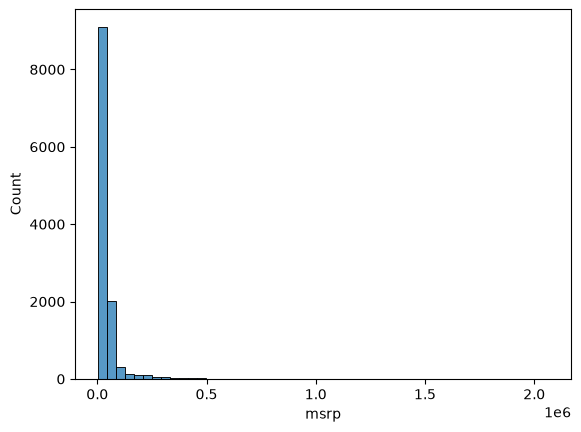

In [13]:
sns.histplot(df.msrp, bins=50)

<Axes: xlabel='msrp', ylabel='Count'>

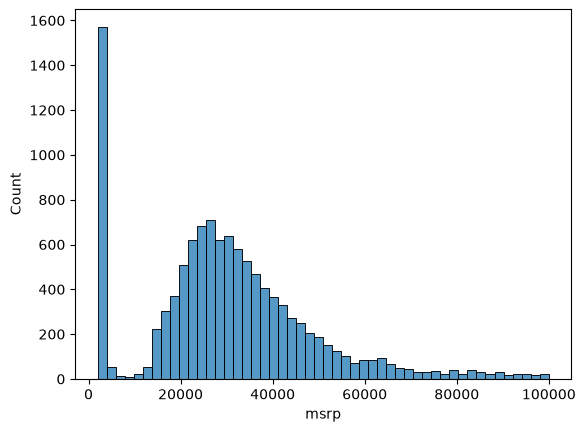

In [14]:
sns.histplot(df.msrp[df.msrp < 100000], bins=50)

In [15]:
import numpy as np
np.log([0 + 1, 1 + 1, 10 + 1, 1000 + 1, 100000 + 1])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [16]:
np.log1p([0, 1, 10, 1000, 100000])

array([ 0.        ,  0.69314718,  2.39789527,  6.90875478, 11.51293546])

In [17]:
price_logs = np.log1p(df.msrp)
price_logs

0        10.739349
1        10.612779
2        10.500977
3        10.290483
4        10.448744
           ...    
11909    10.739024
11910    10.945018
11911    10.832122
11912    10.838031
11913    10.274913
Name: msrp, Length: 11914, dtype: float64

<Axes: xlabel='msrp', ylabel='Count'>

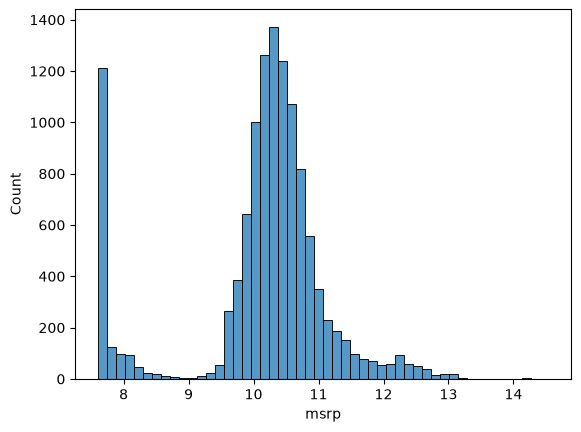

In [ ]:
sns.histplot(price_logs, bins=50)

In [19]:
df.isnull().sum()

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
msrp                    0
dtype: int64

In [20]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

In [21]:
n, n_val, n_test, n_train

(11914, 2382, 2382, 7150)

In [22]:
idx = np.arange(n)
np.random.shuffle(idx)

In [23]:
df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train+n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

In [24]:
np.random.seed(2)

idx = np.arange(n)
np.random.shuffle(idx)

In [25]:
len(df_train), len(df_val), len(df_test)

(7150, 2382, 2382)

In [26]:
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
5591,lexus,gs_460,2010,premium_unleaded_(required),342.0,8.0,automatic,rear_wheel_drive,4.0,"luxury,high-performance",midsize,sedan,24,17,454,54070
887,saab,9000,1998,regular_unleaded,225.0,4.0,manual,front_wheel_drive,4.0,"hatchback,luxury",midsize,4dr_hatchback,25,18,376,2172
4209,ford,escort,2002,regular_unleaded,130.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,31,23,5657,12815
1209,honda,accord_hybrid,2017,regular_unleaded,212.0,4.0,automatic,front_wheel_drive,4.0,hybrid,midsize,sedan,47,49,2202,32905
5702,hummer,h3t,2009,regular_unleaded,239.0,5.0,manual,four_wheel_drive,4.0,"crossover,luxury",compact,crew_cab_pickup,18,14,130,30750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3411,mazda,cx-9,2015,regular_unleaded,273.0,6.0,automatic,front_wheel_drive,4.0,crossover,large,4dr_suv,24,17,586,29985
6823,infiniti,m,2013,premium_unleaded_(required),420.0,8.0,automatic,all_wheel_drive,4.0,"luxury,performance",large,sedan,23,16,190,63700
8,bmw,1_series,2012,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,36900
8522,kia,rio,2016,regular_unleaded,138.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,27,1720,17905


In [27]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [28]:
df_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,msrp
0,lexus,gs_460,2010,premium_unleaded_(required),342.0,8.0,automatic,rear_wheel_drive,4.0,"luxury,high-performance",midsize,sedan,24,17,454,54070
1,saab,9000,1998,regular_unleaded,225.0,4.0,manual,front_wheel_drive,4.0,"hatchback,luxury",midsize,4dr_hatchback,25,18,376,2172
2,ford,escort,2002,regular_unleaded,130.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,31,23,5657,12815
3,honda,accord_hybrid,2017,regular_unleaded,212.0,4.0,automatic,front_wheel_drive,4.0,hybrid,midsize,sedan,47,49,2202,32905
4,hummer,h3t,2009,regular_unleaded,239.0,5.0,manual,four_wheel_drive,4.0,"crossover,luxury",compact,crew_cab_pickup,18,14,130,30750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7145,mazda,cx-9,2015,regular_unleaded,273.0,6.0,automatic,front_wheel_drive,4.0,crossover,large,4dr_suv,24,17,586,29985
7146,infiniti,m,2013,premium_unleaded_(required),420.0,8.0,automatic,all_wheel_drive,4.0,"luxury,performance",large,sedan,23,16,190,63700
7147,bmw,1_series,2012,premium_unleaded_(required),230.0,6.0,manual,rear_wheel_drive,2.0,luxury,compact,convertible,28,18,3916,36900
7148,kia,rio,2016,regular_unleaded,138.0,4.0,automatic,front_wheel_drive,4.0,hatchback,compact,4dr_hatchback,37,27,1720,17905


In [29]:
y_train = np.log1p(df_train.msrp.values)
y_val = np.log1p(df_val.msrp.values)
y_test = np.log1p(df_test.msrp.values)

In [30]:
del df_train['msrp']
del df_val['msrp']
del df_test['msrp']

In [31]:
xi = [453, 11, 86]
w0 = 7.17
w = [0.01, 0.04, 0.002]

In [32]:
def linear_regression(xi):
    n = len(xi)

    pred = w0

    for j in range(n):
        pred = pred + w[j] * xi[j]

    return pred

In [33]:
linear_regression(xi)

12.312

In [34]:
np.expm1(12.312)

np.float64(222347.2221101062)

In [35]:
def dot(xi, w):
    n = len(xi)

    res = 0.0

    for j in range(n):
        res = res + xi[j] * w[j]

    return res

In [36]:
def linear_regression(xi):
    return w0 + dot(xi, w)

In [37]:
w_new = [w0] + w

In [38]:
def linear_regression(xi):
    xi = [1] + xi
    return dot(xi, w_new)

In [39]:
linear_regression(xi)

12.312

In [40]:
x1  = [1, 148, 24, 1385]
x2  = [1, 132, 25, 2031]
x10 = [1, 453, 11, 86]

X = [x1, x2, x10]
X = np.array(X)

In [41]:
w0 = 7.17
w = [0.01, 0.04, 0.002]
w_new = [w0] + w

In [42]:
def linear_regression(X):
    return X.dot(w_new)

In [43]:
linear_regression(X)

array([12.38 , 13.552, 12.312])

In [44]:
X = [
    [148, 24, 1385],
    [132, 25, 2031],
    [453, 11, 86],
    [158, 24, 185],
    [172, 25, 201],
    [413, 11, 86],
    [38,  54, 185],
    [142, 25, 431],
    [453, 31, 86],
]
X = np.array(X)

In [45]:
XTX = X.T.dot(X)
XTX_inv = np.linalg.inv(XTX)

In [46]:
XTX.dot(XTX_inv).round(1)

array([[ 1.,  0.,  0.],
       [-0.,  1.,  0.],
       [ 0.,  0.,  1.]])

In [47]:
y = [100, 200, 150, 250, 100, 200, 150, 250, 120]

In [48]:
w_full = XTX_inv.dot(X.T).dot(y)

In [49]:
ones = np.ones(X.shape[0])
X = np.column_stack([ones, X])
XTX = X.T.dot(X)
XTX_inv = np.linalg.inv(XTX)
w_full = XTX_inv.dot(X.T).dot(y)

In [50]:
w0 = w_full[0]
w = w_full[1:]

In [51]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [52]:
df_train.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity'],
      dtype='str')

In [53]:
base = ['engine_hp', 'engine_cylinders', 'highway_mpg',
        'city_mpg', 'popularity']

In [54]:
X_train = df_train[base].values

In [55]:
w0, w = train_linear_regression(X_train, y_train)

In [56]:
w0, w

(np.float64(nan), array([nan, nan, nan, nan, nan]))

In [57]:
df_train[base].isnull().sum()

engine_hp           40
engine_cylinders    14
highway_mpg          0
city_mpg             0
popularity           0
dtype: int64

In [58]:
X_train = df_train[base].fillna(0).values
w0, w = train_linear_regression(X_train, y_train)

In [59]:
w0,w

(np.float64(7.861826952531741),
 array([ 9.23750624e-03, -1.23801033e-01,  1.51545826e-02,  1.44985990e-02,
        -1.47390409e-05]))

In [60]:
y_pred = w0 + X_train.dot(w)

<Axes: ylabel='Count'>

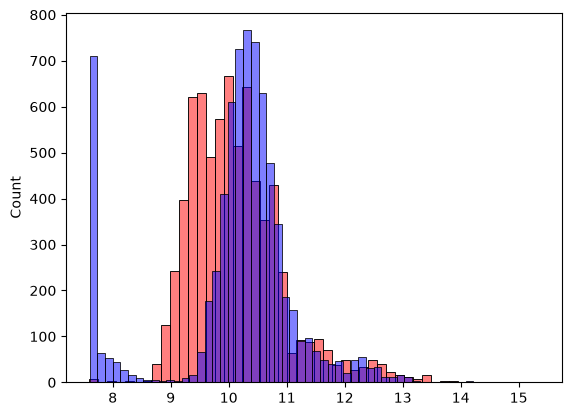

In [61]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [62]:
def rmse(y, y_pred):
    error = y - y_pred
    se = error ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [63]:
rmse(y_train, y_pred)

np.float64(0.745541953356485)

In [64]:
X_train = df_train[base].fillna(0).values

In [65]:
def prepare_X(df):
    df_num = df[base]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [66]:
X_train = prepare_X(df_train)
print(X_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

[[3.420e+02 8.000e+00 2.400e+01 1.700e+01 4.540e+02]
 [2.250e+02 4.000e+00 2.500e+01 1.800e+01 3.760e+02]
 [1.300e+02 4.000e+00 3.100e+01 2.300e+01 5.657e+03]
 ...
 [2.300e+02 6.000e+00 2.800e+01 1.800e+01 3.916e+03]
 [1.380e+02 4.000e+00 3.700e+01 2.700e+01 1.720e+03]
 [3.550e+02 8.000e+00 2.200e+01 1.600e+01 5.490e+02]]


np.float64(0.7665791637617979)

In [ ]:
def prepare_X(df):
    df = df.copy()

    df['age'] = 2017 - df.year
    features = base + ['age']

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [ ]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.5172674217143626)

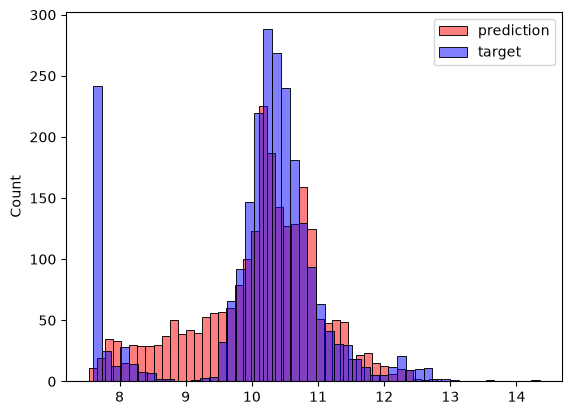

In [69]:
sns.histplot(y_pred, label='prediction', color='red', alpha=0.5, bins=50)
sns.histplot(y_val, label='target', color='blue',  alpha=0.5, bins=50)
plt.legend()

In [ ]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [ ]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.516644654189697)

In [72]:
df.make.value_counts().head()

make
chevrolet     1123
ford           881
volkswagen     809
toyota         746
dodge          626
Name: count, dtype: int64

In [73]:
def prepare_X(df):
    df = df.copy()
    features = base.copy()

    df['age'] = 2017 - df.year
    features.append('age')

    for v in [2, 3, 4]:
        df['num_doors_%s' % v] = (df.number_of_doors == v).astype('int')
        features.append('num_doors_%s' % v)
    
    categorical_variables = [
    'make', 'engine_fuel_type', 'transmission_type', 'driven_wheels',
    'market_category', 'vehicle_size', 'vehicle_style'
]

    categories = {}

    for c in categorical_variables:
        categories[c] = list(df_train[c].value_counts().head().index)

    for c, values in categories.items():
        for v in values:
            df['%s_%s' % (c, v)] = (df[c] == v).astype('int')
            features.append('%s_%s' % (c, v))

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [74]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(505.2849129045852)

In [75]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)

    return w_full[0], w_full[1:]

In [76]:
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=0.01)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
rmse(y_val, y_pred)

np.float64(0.4611260587705023)

In [77]:
for r in [0.0, 0.00001, 0.0001, 0.001, 0.1, 1, 10]:
    X_train = prepare_X(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X(df_val)
    y_pred = w0 + X_val.dot(w)
    score = rmse(y_val, y_pred)

    print(r, w0, score)

0.0 -7.452502839420128e+16 505.2849129045852
1e-05 8.257764755891905 0.46111881770481744
0.0001 6.2794430472286065 0.46111888903665244
0.001 6.270188890371556 0.46111952235721687
0.1 6.142976767953429 0.4612102437551852
1 5.498650199576686 0.4626619688819024
10 4.224962641183214 0.4790973161360633


In [78]:
r = 0.001
X_train = prepare_X(df_train)
w0, w = train_linear_regression_reg(X_train, y_train, r=r)

X_val = prepare_X(df_val)
y_pred = w0 + X_val.dot(w)
score = rmse(y_val, y_pred)
score

np.float64(0.46111952235721687)

In [79]:
df_full_train = pd.concat([df_train, df_val])

In [80]:
df_full_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,lexus,gs_460,2010,premium_unleaded_(required),342.0,8.0,automatic,rear_wheel_drive,4.0,"luxury,high-performance",midsize,sedan,24,17,454
1,saab,9000,1998,regular_unleaded,225.0,4.0,manual,front_wheel_drive,4.0,"hatchback,luxury",midsize,4dr_hatchback,25,18,376
2,ford,escort,2002,regular_unleaded,130.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,31,23,5657
3,honda,accord_hybrid,2017,regular_unleaded,212.0,4.0,automatic,front_wheel_drive,4.0,hybrid,midsize,sedan,47,49,2202
4,hummer,h3t,2009,regular_unleaded,239.0,5.0,manual,four_wheel_drive,4.0,"crossover,luxury",compact,crew_cab_pickup,18,14,130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2377,buick,rendezvous,2007,regular_unleaded,196.0,6.0,automatic,front_wheel_drive,4.0,crossover,midsize,4dr_suv,23,17,155
2378,chevrolet,cobalt,2010,regular_unleaded,155.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,37,25,1385
2379,volkswagen,beetle,2015,regular_unleaded,170.0,4.0,manual,front_wheel_drive,2.0,hatchback,compact,2dr_hatchback,33,24,873
2380,mercedes-benz,glk-class,2013,premium_unleaded_(required),302.0,6.0,automatic,all_wheel_drive,4.0,"crossover,luxury",midsize,4dr_suv,24,19,617


In [81]:
df_full_train = df_full_train.reset_index(drop=True)
df_full_train

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity
0,lexus,gs_460,2010,premium_unleaded_(required),342.0,8.0,automatic,rear_wheel_drive,4.0,"luxury,high-performance",midsize,sedan,24,17,454
1,saab,9000,1998,regular_unleaded,225.0,4.0,manual,front_wheel_drive,4.0,"hatchback,luxury",midsize,4dr_hatchback,25,18,376
2,ford,escort,2002,regular_unleaded,130.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,31,23,5657
3,honda,accord_hybrid,2017,regular_unleaded,212.0,4.0,automatic,front_wheel_drive,4.0,hybrid,midsize,sedan,47,49,2202
4,hummer,h3t,2009,regular_unleaded,239.0,5.0,manual,four_wheel_drive,4.0,"crossover,luxury",compact,crew_cab_pickup,18,14,130
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9527,buick,rendezvous,2007,regular_unleaded,196.0,6.0,automatic,front_wheel_drive,4.0,crossover,midsize,4dr_suv,23,17,155
9528,chevrolet,cobalt,2010,regular_unleaded,155.0,4.0,manual,front_wheel_drive,2.0,NaN,compact,coupe,37,25,1385
9529,volkswagen,beetle,2015,regular_unleaded,170.0,4.0,manual,front_wheel_drive,2.0,hatchback,compact,2dr_hatchback,33,24,873
9530,mercedes-benz,glk-class,2013,premium_unleaded_(required),302.0,6.0,automatic,all_wheel_drive,4.0,"crossover,luxury",midsize,4dr_suv,24,19,617


In [83]:
X_full_train = prepare_X(df_full_train)
X_full_train

array([[342.,   8.,  24., ...,   0.,   0.,   0.],
       [225.,   4.,  25., ...,   0.,   0.,   1.],
       [130.,   4.,  31., ...,   1.,   0.,   0.],
       ...,
       [170.,   4.,  33., ...,   0.,   0.,   0.],
       [302.,   6.,  24., ...,   0.,   0.,   0.],
       [416.,   8.,  24., ...,   0.,   0.,   0.]], shape=(9532, 41))

In [84]:
y_full_train = np.concatenate([y_train, y_val])

In [85]:
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

In [86]:
X_test = prepare_X(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
score

np.float64(0.4562534604746055)

In [ ]:
car = df_test.iloc[20].to_dict()
car

{'make': 'chevrolet',
 'model': 'colorado',
 'year': 2015,
 'engine_fuel_type': 'regular_unleaded',
 'engine_hp': 305.0,
 'engine_cylinders': 6.0,
 'transmission_type': 'automatic',
 'driven_wheels': 'four_wheel_drive',
 'number_of_doors': 4.0,
 'market_category': nan,
 'vehicle_size': 'compact',
 'vehicle_style': 'crew_cab_pickup',
 'highway_mpg': 24,
 'city_mpg': 17,
 'popularity': 1385}

In [ ]:
df_small = pd.DataFrame([car])
X_small = prepare_X(df_small)

In [97]:
df_small.make

0    chevrolet
Name: make, dtype: str

In [98]:
y_pred = w0 + X_small.dot(w)
y_pred = y_pred[0]
y_pred

np.float64(10.712284473308024)

In [99]:
# And remember: this is the logarithm of the price, not the price itself. To undo the logarithm, we take the exponent:
np.expm1(y_pred)

np.float64(44903.10402858815)

In [100]:
np.expm1(y_test[20])

np.float64(29705.00000000002)